In [1]:
%pip install -q mlflow hmmlearn pandas numpy matplotlib scipy scikit-learn

In [2]:
import os
import json
import pickle
import time
import subprocess
from pathlib import Path

import mlflow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler
from scipy.special import logsumexp
from scipy.stats import norm
from IPython.display import display

In [3]:
from google.colab import files

uploaded = files.upload()

file_name = "rice_hmm_clean.csv"

if file_name not in uploaded and not os.path.exists("/content/" + file_name):
    raise FileNotFoundError("Upload rice_hmm_clean.csv")

df = pd.read_csv("/content/" + file_name)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Saving rice_hmm_clean.csv to rice_hmm_clean.csv
Dataset shape: (10350, 29)
Columns: ['Dist Code', 'Year', 'State Name', 'Dist Name', 'RICE AREA (1000 ha)', 'RICE PRODUCTION (1000 tons)', 'RICE YIELD (Kg per ha)', 'GROSS CROPPED AREA (1000 ha)', 'NITROGEN CONSUMPTION (tons)', 'PHOSPHATE CONSUMPTION (tons)', 'POTASH CONSUMPTION (tons)', 'TOTAL FERTILISER CONSUMPTION (tons)', 'GROSS IRRIGATED AREA (1000 ha)', 'Winter JAN-FEB MAXIMUM TEMPERATURE (Centigrate)', 'Summer MAR-MAY MAXIMUM TEMPERATURE (Centigrate)', 'Rainy JUN-SEP MAXIMUM TEMPERATURE (Centigrate)', 'Autumn OCT-DEC MAXIMUM TEMPERATURE (Centigrate)', 'Winter JAN-FEB MINIMUM TEMPERATURE (Centigrate)', 'Summer MAR-MAY MINIMUM TEMPERATURE (Centigrate)', 'Rainy JUN-SEP MINIMUM TEMPERATURE (Centigrate)', 'Autumn OCT-DEC MINIMUM TEMPERATURE (Centigrate)', 'Winter JAN-FEB PERCIPITATION (Millimeters)', 'Summer MAR-MAY PERCIPITATION (Millimeters)', 'Rainy JUN-SEP PERCIPITATION (Millimeters)', 'Autumn OCT-DEC PERCIPITATION (Millimeters)', '

,Dist Code,Year,State Name,Dist Name,RICE AREA (1000 ha),RICE PRODUCTION (1000 tons),RICE YIELD (Kg per ha),GROSS CROPPED AREA (1000 ha),NITROGEN CONSUMPTION (tons),PHOSPHATE CONSUMPTION (tons),...,Rainy JUN-SEP MINIMUM TEMPERATURE (Centigrate),Autumn OCT-DEC MINIMUM TEMPERATURE (Centigrate),Winter JAN-FEB PERCIPITATION (Millimeters),Summer MAR-MAY PERCIPITATION (Millimeters),Rainy JUN-SEP PERCIPITATION (Millimeters),Autumn OCT-DEC PERCIPITATION (Millimeters),Winter JAN-FEB ACTUAL EVAPOTRANSPIRATION (Millimeters),Summer MAR-MAY ACTUAL EVAPOTRANSPIRATION (Millimeters),Rainy JUN-SEP ACTUAL EVAPOTRANSPIRATION (Millimeters),Autumn OCT-DEC ACTUAL EVAPOTRANSPIRATION (Millimeters)
0,1,1990,Chhattisgarh,Durg,397.899994,481.399994,1210,758.000000,11776.0,5834.0,...,23.957500,16.920000,17.290001,38.803333,349.524994,35.036667,41.785000,45.686668,123.572502,70.076668
1,1,1991,Chhattisgarh,Durg,393.200012,508.600006,1293,758.400024,12401.0,9870.0,...,24.514999,16.469999,5.550000,17.613333,278.737488,10.393333,40.724998,28.139999,126.605003,56.096668
2,1,1992,Chhattisgarh,Durg,398.399994,514.500000,1291,760.500000,17443.0,10561.0,...,24.850000,16.523333,1.685000,5.360000,250.187500,9.443334,28.180000,13.893333,105.184998,55.189999
3,1,1993,Chhattisgarh,Durg,410.200012,569.099976,1387,796.299988,14996.0,8640.0,...,25.067499,16.376667,3.495000,33.980000,285.902496,23.940001,30.385000,40.889999,123.445000,64.756668
4,1,1994,Chhattisgarh,Durg,430.100006,601.700012,1399,818.309998,18021.0,8502.0,...,23.885000,16.320000,12.740000,10.810000,376.287506,29.623333,42.889999,20.110001,126.495003,67.676666


In [4]:
district_column = "Dist Name"
year_column = "Year"

feature_columns = [
    "RICE YIELD (Kg per ha)",
    "Rainy JUN-SEP MAXIMUM TEMPERATURE (Centigrate)",
    "Rainy JUN-SEP PERCIPITATION (Millimeters)"
]

required_columns = [district_column, year_column] + feature_columns
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError("Missing columns: " + str(missing_columns))

data = df[
    df[district_column].astype(str).str.strip().str.lower() == "durg"
].copy()

data[year_column] = pd.to_numeric(data[year_column], errors="coerce")

for col in feature_columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.dropna(subset=[year_column] + feature_columns)
data = data.sort_values(year_column).drop_duplicates(subset=[year_column])
data = data.reset_index(drop=True)

if len(data) < 10:
    raise ValueError("Not enough valid records for Durg district.")

years = data[year_column].to_numpy()
X = data[feature_columns].to_numpy(dtype=float)

print("District: Durg")
print("Number of records:", len(data))
print("Year range:", years.min(), "to", years.max())
display(data[[year_column] + feature_columns].head())

District: Durg
Number of records: 26
Year range: 1990 to 2015


,Year,RICE YIELD (Kg per ha),Rainy JUN-SEP MAXIMUM TEMPERATURE (Centigrate),Rainy JUN-SEP PERCIPITATION (Millimeters)
0,1990,1210,31.297501,349.524994
1,1991,1293,31.972500,278.737488
2,1992,1291,32.384998,250.187500
3,1993,1387,32.424999,285.902496
4,1994,1399,31.285000,376.287506


In [5]:
split_point = int(len(X) * 0.8)

X_train = X[:split_point]
X_test = X[split_point:]
test_years = years[split_point:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training records:", len(X_train_scaled))
print("Testing records:", len(X_test_scaled))

Training records: 20
Testing records: 6


In [6]:
hmm_model = GaussianHMM(
    n_components=2,
    covariance_type="diag",
    n_iter=200,
    random_state=42,
    min_covar=1e-3
)

hmm_model.fit(X_train_scaled)

train_log_likelihood = hmm_model.score(X_train_scaled)
test_log_likelihood = hmm_model.score(X_test_scaled)

print("HMM training completed")
print("Training log likelihood:", train_log_likelihood)
print("Testing log likelihood:", test_log_likelihood)
print("Initial probabilities:")
print(hmm_model.startprob_)
print("Transition matrix:")
print(hmm_model.transmat_)

HMM training completed
Training log likelihood: -69.81616189352526
Testing log likelihood: -184.50485179738493
Initial probabilities:
[6.59387167e-60 1.00000000e+00]
Transition matrix:
[[9.41177272e-001 5.88227282e-002]
 [1.00000000e+000 2.21601140e-265]]


In [7]:
def get_log_emissions(model, observations):
    covariance = np.asarray(model.covars_)

    if covariance.ndim == 3:
        covariance = np.diagonal(covariance, axis1=1, axis2=2)

    log_emissions = np.zeros((len(observations), model.n_components))

    for state in range(model.n_components):
        log_emissions[:, state] = np.sum(
            norm.logpdf(
                observations,
                loc=model.means_[state],
                scale=np.sqrt(covariance[state])
            ),
            axis=1
        )

    return log_emissions


def forward_algorithm(model, observations):
    log_emissions = get_log_emissions(model, observations)
    log_start = np.log(np.clip(model.startprob_, 1e-300, None))
    log_transition = np.log(np.clip(model.transmat_, 1e-300, None))

    time_steps, states = log_emissions.shape
    alpha = np.zeros((time_steps, states))

    alpha[0] = log_start + log_emissions[0]

    for t in range(1, time_steps):
        for j in range(states):
            alpha[t, j] = log_emissions[t, j] + logsumexp(
                alpha[t - 1] + log_transition[:, j]
            )

    likelihood = logsumexp(alpha[-1])
    return alpha, float(likelihood)


def backward_algorithm(model, observations):
    log_emissions = get_log_emissions(model, observations)
    log_start = np.log(np.clip(model.startprob_, 1e-300, None))
    log_transition = np.log(np.clip(model.transmat_, 1e-300, None))

    time_steps, states = log_emissions.shape
    beta = np.zeros((time_steps, states))

    for t in range(time_steps - 2, -1, -1):
        for i in range(states):
            beta[t, i] = logsumexp(
                log_transition[i]
                + log_emissions[t + 1]
                + beta[t + 1]
            )

    likelihood = logsumexp(log_start + log_emissions[0] + beta[0])
    return beta, float(likelihood)

In [8]:
alpha, forward_log_likelihood = forward_algorithm(hmm_model, X_test_scaled)
beta, backward_log_likelihood = backward_algorithm(hmm_model, X_test_scaled)

log_posterior = alpha + beta - forward_log_likelihood
posterior = np.exp(log_posterior)
posterior = posterior / posterior.sum(axis=1, keepdims=True)

print("Forward log likelihood:", forward_log_likelihood)
print("Backward log likelihood:", backward_log_likelihood)
print("Difference:", abs(forward_log_likelihood - backward_log_likelihood))
display(pd.DataFrame(posterior, columns=["State 0", "State 1"]).head())

Forward log likelihood: -184.5048517973849
Backward log likelihood: -184.50485179738484
Difference: 5.684341886080802e-14


,State 0,State 1
0,1.0,5.249706e-280
1,1.0,3.029470e-125
2,1.0,2.060186e-226
3,1.0,2.328959e-08
4,1.0,0.000000e+00


In [9]:
def sum_product_algorithm(model, observations):
    alpha, sequence_log_likelihood = forward_algorithm(model, observations)
    beta, backward_likelihood = backward_algorithm(model, observations)

    posterior = np.exp(alpha + beta - sequence_log_likelihood)
    posterior = posterior / posterior.sum(axis=1, keepdims=True)

    log_transition = np.log(np.clip(model.transmat_, 1e-300, None))
    log_emissions = get_log_emissions(model, observations)

    pairwise = []

    for t in range(len(observations) - 1):
        log_xi = (
            alpha[t][:, None]
            + log_transition
            + log_emissions[t + 1][None, :]
            + beta[t + 1][None, :]
            - sequence_log_likelihood
        )

        xi = np.exp(log_xi)
        xi = xi / xi.sum()
        pairwise.append(xi)

    return posterior, np.asarray(pairwise), sequence_log_likelihood


posterior, pairwise_probabilities, sum_product_log_likelihood = sum_product_algorithm(
    hmm_model, X_test_scaled
)

print("Sum-Product completed")
print("Posterior probabilities shape:", posterior.shape)
print("Pairwise probabilities shape:", pairwise_probabilities.shape)
print("Mean posterior confidence:", np.mean(np.max(posterior, axis=1)))

Sum-Product completed
Posterior probabilities shape: (6, 2)
Pairwise probabilities shape: (5, 2, 2)
Mean posterior confidence: 0.999999996118402


In [10]:
def viterbi_algorithm(model, observations):
    log_emissions = get_log_emissions(model, observations)
    log_start = np.log(np.clip(model.startprob_, 1e-300, None))
    log_transition = np.log(np.clip(model.transmat_, 1e-300, None))

    time_steps, states = log_emissions.shape
    delta = np.zeros((time_steps, states), dtype=float)
    back_pointer = np.zeros((time_steps, states), dtype=int)

    delta[0] = log_start + log_emissions[0]

    for t in range(1, time_steps):
        for j in range(states):
            candidates = delta[t - 1] + log_transition[:, j]
            back_pointer[t, j] = np.argmax(candidates)
            delta[t, j] = np.max(candidates) + log_emissions[t, j]

    best_path = np.zeros(time_steps, dtype=int)
    best_path[-1] = np.argmax(delta[-1])

    for t in range(time_steps - 2, -1, -1):
        best_path[t] = back_pointer[t + 1, best_path[t + 1]]

    best_path_log_probability = np.max(delta[-1])
    return best_path, float(best_path_log_probability)


viterbi_states, viterbi_log_probability = viterbi_algorithm(
    hmm_model, X_test_scaled
)

print("Viterbi completed")
print("Most likely hidden states:")
print(viterbi_states)
print("Best path log probability:", viterbi_log_probability)

library_states = hmm_model.predict(X_test_scaled)
print("Matches hmmlearn Viterbi:", np.array_equal(viterbi_states, library_states))

Viterbi completed
Most likely hidden states:
[0 0 0 0 0 0]
Best path log probability: -184.5048518206745
Matches hmmlearn Viterbi: True


In [11]:
results = pd.DataFrame({
    "Year": test_years,
    "Actual_Rice_Yield": X_test[:, 0],
    "State_0_Probability": posterior[:, 0],
    "State_1_Probability": posterior[:, 1],
    "Viterbi_State": viterbi_states
})

display(results)

print("Forward likelihood:", forward_log_likelihood)
print("Backward likelihood:", backward_log_likelihood)
print("Sum-Product likelihood:", sum_product_log_likelihood)
print("Viterbi path log probability:", viterbi_log_probability)

,Year,Actual_Rice_Yield,State_0_Probability,State_1_Probability,Viterbi_State
0,2010,1775.0,1.0,5.249706e-280,0
1,2011,1922.0,1.0,3.029470e-125,0
2,2012,2282.0,1.0,2.060186e-226,0
3,2013,1942.0,1.0,2.328959e-08,0
4,2014,1855.0,1.0,0.000000e+00,0
5,2015,1342.0,1.0,1.588671e-152,0


Forward likelihood: -184.5048517973849
Backward likelihood: -184.50485179738484
Sum-Product likelihood: -184.5048517973849
Viterbi path log probability: -184.5048518206745


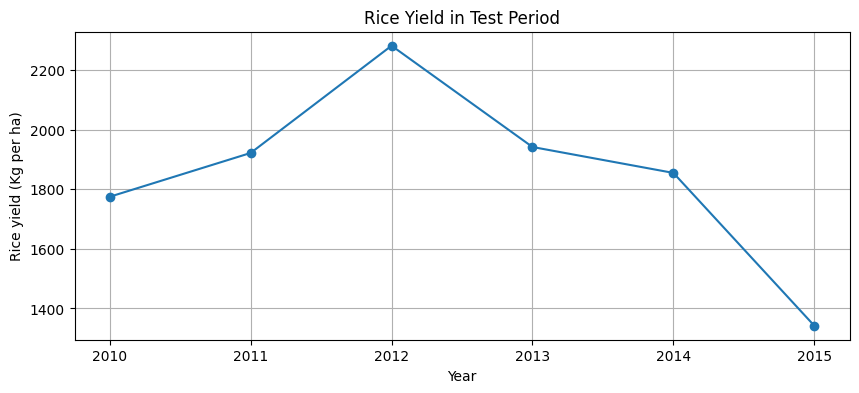

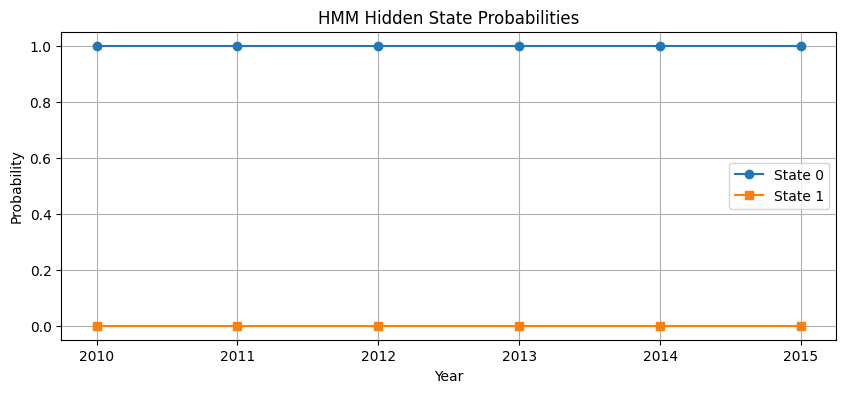

In [12]:
output_folder = Path("/content/rice_hmm_outputs")
output_folder.mkdir(exist_ok=True)

model_file = output_folder / "rice_hmm_model.pkl"
results_file = output_folder / "rice_hmm_results.csv"
transition_file = output_folder / "transition_matrix.csv"
posterior_file = output_folder / "posterior_probabilities.csv"

with open(model_file, "wb") as file:
    pickle.dump(
        {
            "model": hmm_model,
            "scaler": scaler,
            "features": feature_columns
        },
        file
    )

results.to_csv(results_file, index=False)
pd.DataFrame(hmm_model.transmat_).to_csv(transition_file, index=False)
pd.DataFrame(posterior).to_csv(posterior_file, index=False)

plt.figure(figsize=(10, 4))
plt.plot(test_years, X_test[:, 0], marker="o")
plt.xlabel("Year")
plt.ylabel("Rice yield (Kg per ha)")
plt.title("Rice Yield in Test Period")
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(test_years, posterior[:, 0], marker="o", label="State 0")
plt.plot(test_years, posterior[:, 1], marker="s", label="State 1")
plt.xlabel("Year")
plt.ylabel("Probability")
plt.title("HMM Hidden State Probabilities")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
mlflow.set_tracking_uri("sqlite:////content/mlflow.db")

experiment_name = "Rice_HMM_Tracking"
artifact_folder = Path("/content/mlflow_artifacts")
artifact_folder.mkdir(exist_ok=True)

experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment is None:
    experiment_id = mlflow.create_experiment(
        experiment_name,
        artifact_location=artifact_folder.resolve().as_uri()
    )
else:
    experiment_id = experiment.experiment_id

mlflow.set_experiment(experiment_name)

print("MLflow experiment:", experiment_name)
print("Experiment ID:", experiment_id)
print("Tracking URI:", mlflow.get_tracking_uri())

2026/11/19 07:32:55 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/19 07:32:55 INFO mlflow.store.db.utils: Updating database tables


MLflow experiment: Rice_HMM_Tracking
Experiment ID: 1
Tracking URI: sqlite:////content/mlflow.db


In [14]:
common_parameters = {
    "dataset": "rice_hmm_clean.csv",
    "district": "Durg",
    "model": "GaussianHMM",
    "number_of_states": 2,
    "covariance_type": "diag",
    "training_records": len(X_train_scaled),
    "testing_records": len(X_test_scaled),
    "features": json.dumps(feature_columns)
}

algorithm_runs = [
    {
        "name": "Forward_Algorithm",
        "algorithm": "Forward",
        "metrics": {
            "log_likelihood": forward_log_likelihood
        },
        "artifacts": [model_file, results_file]
    },
    {
        "name": "Backward_Algorithm",
        "algorithm": "Backward",
        "metrics": {
            "log_likelihood": backward_log_likelihood
        },
        "artifacts": [model_file, results_file]
    },
    {
        "name": "Sum_Product_Algorithm",
        "algorithm": "Sum-Product",
        "metrics": {
            "log_likelihood": sum_product_log_likelihood,
            "mean_posterior_confidence": float(np.mean(np.max(posterior, axis=1)))
        },
        "artifacts": [model_file, posterior_file, transition_file, results_file]
    },
    {
        "name": "Viterbi_Algorithm",
        "algorithm": "Viterbi",
        "metrics": {
            "best_path_log_probability": viterbi_log_probability,
            "number_of_test_states": len(viterbi_states)
        },
        "artifacts": [model_file, results_file]
    }
]

for item in algorithm_runs:
    with mlflow.start_run(run_name=item["name"]):
        mlflow.log_params(common_parameters)
        mlflow.log_param("algorithm", item["algorithm"])
        mlflow.log_metrics({
            key: float(value)
            for key, value in item["metrics"].items()
        })

        for artifact in item["artifacts"]:
            mlflow.log_artifact(str(artifact))

        print(item["name"], "logged successfully")

Forward_Algorithm logged successfully
Backward_Algorithm logged successfully
Sum_Product_Algorithm logged successfully
Viterbi_Algorithm logged successfully


In [15]:
experiment = mlflow.get_experiment_by_name(experiment_name)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["attributes.start_time ASC"]
)

print("Number of MLflow runs:", len(runs))

columns_to_show = [
    "tags.mlflow.runName",
    "params.algorithm",
    "metrics.log_likelihood",
    "metrics.mean_posterior_confidence",
    "metrics.best_path_log_probability"
]

columns_to_show = [col for col in columns_to_show if col in runs.columns]
display(runs[columns_to_show])

expected_runs = {
    "Forward_Algorithm",
    "Backward_Algorithm",
    "Sum_Product_Algorithm",
    "Viterbi_Algorithm"
}

actual_runs = set(runs["tags.mlflow.runName"].dropna())
assert expected_runs.issubset(actual_runs), "Some MLflow runs are missing"

print("All four algorithm runs are recorded in MLflow.")

Number of MLflow runs: 4


,tags.mlflow.runName,params.algorithm,metrics.log_likelihood,metrics.mean_posterior_confidence,metrics.best_path_log_probability
0,Forward_Algorithm,Forward,-184.504852,NaN,NaN
1,Backward_Algorithm,Backward,-184.504852,NaN,NaN
2,Sum_Product_Algorithm,Sum-Product,-184.504852,1.0,NaN
3,Viterbi_Algorithm,Viterbi,NaN,NaN,-184.504852


All four algorithm runs are recorded in MLflow.


In [16]:
import os
import sys
import time
import socket
import subprocess
import requests
import mlflow
from google.colab import output

# 1. Find an available port
PORT = 5001

for p in [5001, 5002, 5003, 5004]:
    s = socket.socket()
    result = s.connect_ex(("127.0.0.1", p))
    s.close()
    if result != 0:
        PORT = p
        break
else:
    raise RuntimeError("No available port found")

# 2. Create storage folders
os.makedirs("/content/mlflow-artifacts", exist_ok=True)

# 3. Start MLflow server
log = open("/content/mlflow.log", "w")

mlflow_server = subprocess.Popen(
    [
        sys.executable, "-m", "mlflow", "server",
        "--host", "0.0.0.0",
        "--port", str(PORT),
        "--backend-store-uri", "sqlite:////content/mlflow.db",
        "--default-artifact-root", "/content/mlflow-artifacts",
        "--allowed-hosts", "*",
        "--cors-allowed-origins", "*"
    ],
    stdout=log,
    stderr=subprocess.STDOUT
)

# 4. Wait for server
LOCAL_URL = f"http://127.0.0.1:{PORT}"
ready = False

for _ in range(40):
    try:
        # Target the root landing page which is guaranteed to return 200 OK via GET
        r = requests.get(LOCAL_URL + "/", timeout=2)
        if r.status_code == 200:
            ready = True
            break
    except requests.RequestException:
        pass
    time.sleep(2)

if not ready:
    log.flush()
    print(open("/content/mlflow.log").read()[-5000:])
    raise RuntimeError("MLflow failed to start. See logs above.")

# 5. Configure experiment
mlflow.set_tracking_uri(LOCAL_URL)
mlflow.set_experiment("Crop_Yield_ML_Experiments")

# 6. Generate dashboard URL
dashboard_url = output.eval_js(
    f"google.colab.kernel.proxyPort({PORT})"
)

print("===============================")
print("MLFLOW STARTED SUCCESSFULLY")
print("===============================")
print("MLflow Version:", mlflow.__version__)
print("Port:", PORT)
print("Experiment: Crop_Yield_ML_Experiments")
print("\nOPEN YOUR MLFLOW DASHBOARD:")
print(dashboard_url)

2026/11/19 07:33:50 INFO mlflow.tracking.fluent: Experiment with name 'Crop_Yield_ML_Experiments' does not exist. Creating a new experiment.


MLFLOW STARTED SUCCESSFULLY
MLflow Version: 3.18.0
Port: 5001
Experiment: Crop_Yield_ML_Experiments

OPEN YOUR MLFLOW DASHBOARD:
https://5001-m-s-usc1c5-2jmr2ql50aph5-c.us-central1.prod.r.colab.dev
